# Data-Driven Clothing for Interactive Applications
**UE24CS352A Machine Learning - Mini Project**
Team: 26
Rajgopal Deshpande (PES2U24CS395)
Rohan Rajeev Chirbi (PES2U24CS485)
 &nbsp;|&nbsp; Problem no. : 47
Based on Xue & Wu, *Data-Driven Clothing for Interactive Applications*.

**Task:** predict coat vertex offsets (2,170 vertices x 3 = 6,510 outputs) from 14 joint-rotation quaternions (56 inputs), using PCA + a fully-connected network, compared with a linear-regression baseline.

**Important:** the paper's dataset (Blender skinning + PhysBAM simulation) is not available, so this notebook uses a **synthetic stand-in dataset** with the same shapes (linear part + smooth nonlinear part + noise). Absolute errors are therefore *not* comparable to the paper; the comparison between models is what matters.

Run **Runtime > Run all**. Set `QUICK = True` in the next cell first if you only want to check that everything runs (about a minute).

## 0. Configuration

In [ ]:
QUICK = False                 # True: 5 epochs per model (smoke test)
EPOCHS = 5 if QUICK else 1000 # paper: 1000
LR = 1e-3                     # learning rate used for ALL models in the main experiment
BATCH = 32
VERTS = 2170                  # paper: 2,170 vertices -> 6,510 outputs
JOINTS = 14
N_EXAMPLES = 10000
N_TRAIN, N_VAL = 6000, 2000   # remainder (after cleaning) is the test set
KEEP_QUANTILE = 0.98          # drop the 2% of examples with the largest offset distance
SEED = 0
RUN_LR_ABLATION = False       # optional extra experiment (Section 7); needs extra training time

In [ ]:
import time, json
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt

DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
print("device:", DEV, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu130


## 1. Dataset
Input: 14 joint quaternions (w,x,y,z) = 56-d. Output: per-vertex (x,y,z) offsets from the skinned coat to the simulated coat = 6,510-d.
We then drop the examples with the largest mean squared offset distance (mimicking the paper's removal of faulty simulations) and split 6,000 / 2,000 / remainder.

raw: (10000, 56) (10000, 6510)
removed 200 examples above 0.0906; 9800 remain


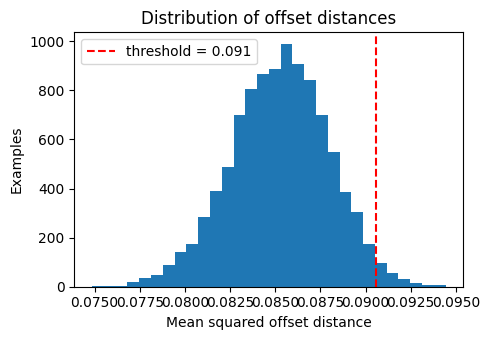

train/val/test = 6000/2000/1800  in=56 out=6510


In [ ]:
def random_quats(n, joints, rng):
    q = rng.normal(size=(n, joints, 4))
    q /= np.linalg.norm(q, axis=-1, keepdims=True)
    q *= np.sign(q[..., :1] + 1e-9)      # w >= 0 (q and -q are the same rotation)
    return q.reshape(n, joints * 4).astype(np.float32)

def make_dataset(n, joints, verts, seed=0):
    rng = np.random.default_rng(seed)
    X = random_quats(n, joints, rng)
    d_in, d_out = joints * 4, verts * 3
    W_lin = rng.normal(size=(d_in, d_out)) * 0.02
    H = rng.normal(size=(d_in, 64))
    W_nl = rng.normal(size=(64, d_out)) * 0.02
    Y = X @ W_lin + np.tanh(2.0 * (X @ H)) @ W_nl     # linear (skinning-like) + nonlinear part
    Y += rng.normal(size=Y.shape) * 1e-3              # small noise
    return X, Y.astype(np.float32)

X, Y = make_dataset(N_EXAMPLES, JOINTS, VERTS, seed=0)
print("raw:", X.shape, Y.shape)

dist = (Y.reshape(len(Y), -1, 3) ** 2).sum(-1).mean(1)     # mean squared L2 distance per example
thr = np.quantile(dist, KEEP_QUANTILE)
mask = dist <= thr
Xc, Yc = X[mask], Y[mask]
print(f"removed {(~mask).sum()} examples above {thr:.4f}; {len(Xc)} remain")

plt.figure(figsize=(5, 3.5))
plt.hist(dist, bins=30); plt.axvline(thr, color="r", ls="--", label=f"threshold = {thr:.3f}")
plt.xlabel("Mean squared offset distance"); plt.ylabel("Examples")
plt.title("Distribution of offset distances"); plt.legend(); plt.tight_layout(); plt.show()

to_dev = lambda a: torch.tensor(a, device=DEV)
train_set = (to_dev(Xc[:N_TRAIN]), to_dev(Yc[:N_TRAIN]))
val_set   = (to_dev(Xc[N_TRAIN:N_TRAIN + N_VAL]), to_dev(Yc[N_TRAIN:N_TRAIN + N_VAL]))
test_set  = (to_dev(Xc[N_TRAIN + N_VAL:]), to_dev(Yc[N_TRAIN + N_VAL:]))
d_in, d_out = Xc.shape[1], Yc.shape[1]
V = d_out // 3
print(f"train/val/test = {len(train_set[0])}/{len(val_set[0])}/{len(test_set[0])}  in={d_in} out={d_out}")

## 2. PCA on the training offsets
PCA is fitted on the **training set only**. Principal components are the rows of `Vt`; a mesh is reconstructed as `x = sum_l c_l u_l + mu`.

components for 90% variance: 56 | for 99% variance: 100
PCA reconstruction floor (avg per-vertex sq. error) at k=64: 4.801e-03
PCA reconstruction floor (avg per-vertex sq. error) at k=128: 2.870e-06


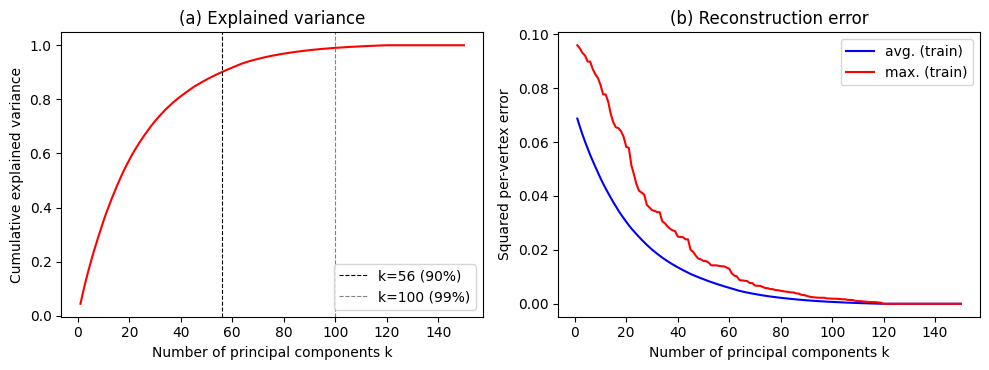

In [ ]:
Y64 = train_set[1].double().cpu()
mu64 = Y64.mean(0)
Yc64 = Y64 - mu64
_, S, Vt64 = torch.linalg.svd(Yc64, full_matrices=False)     # may take a minute or two
explained = ((S ** 2).cumsum(0) / (S ** 2).sum()).numpy()
k90 = int((explained < 0.90).sum()) + 1
k99 = int((explained < 0.99).sum()) + 1
print(f"components for 90% variance: {k90} | for 99% variance: {k99}")

# Reconstruction error vs k (components are orthonormal: residual = ||x||^2 - sum of squared coefficients)
K_MAX = 150
C = Yc64 @ Vt64[:K_MAX].T
resid = (Yc64 ** 2).sum(1)[:, None] - (C ** 2).cumsum(1)
per_vertex = resid.clamp(min=0) / V                 # mean squared per-vertex error per example
avg_err, max_err = per_vertex.mean(0).numpy(), per_vertex.max(0).values.numpy()
for k in (64, 128):
    print(f"PCA reconstruction floor (avg per-vertex sq. error) at k={k}: {avg_err[k-1]:.3e}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(range(1, K_MAX + 1), explained[:K_MAX], "r")
ax[0].axvline(k90, ls="--", c="k", lw=.8, label=f"k={k90} (90%)")
if k99 <= K_MAX: ax[0].axvline(k99, ls="--", c="gray", lw=.8, label=f"k={k99} (99%)")
ax[0].set(xlabel="Number of principal components k", ylabel="Cumulative explained variance", title="(a) Explained variance"); ax[0].legend()
ax[1].plot(range(1, K_MAX + 1), avg_err, "b", label="avg. (train)")
ax[1].plot(range(1, K_MAX + 1), max_err, "r", label="max. (train)")
ax[1].set(xlabel="Number of principal components k", ylabel="Squared per-vertex error", title="(b) Reconstruction error"); ax[1].legend()
plt.tight_layout(); plt.show()

mu = mu64.float().to(DEV)
Vt = Vt64.float().to(DEV)
del Yc64, C, resid, per_vertex

## 3. Models and training
* **Linear regression baseline**: a network with zero hidden layers (56 -> 6,510).
* **MLP, direct**: ReLU 128 -> 256 -> 6,510 vertex offsets.
* **MLP + PCA**: ReLU 128 -> 256 -> *k* PCA coefficients -> a **frozen "PC layer"** (weights = principal components, bias = mean) that reconstructs the offsets.

Loss: MSE on the reconstructed offsets. Optimiser: Adam, batch size 32. The best epoch is selected on **validation** MSE.

In [ ]:
def build_model(hidden, k=None):
    layers, prev = [], d_in
    for h in hidden:
        layers += [nn.Linear(prev, h), nn.ReLU()]; prev = h
    if k is None:
        layers.append(nn.Linear(prev, d_out))
    else:
        layers.append(nn.Linear(prev, k))                    # predicts PCA coefficients c_l
        pc = nn.Linear(k, d_out)                             # fixed PC layer: sum c_l u_l + mu
        pc.weight.data = Vt[:k].T.contiguous().clone()
        pc.bias.data = mu.clone()
        for p in pc.parameters(): p.requires_grad = False
        layers.append(pc)
    return nn.Sequential(*layers).to(DEV)

def mse(model, X_, Y_):
    model.eval()
    with torch.no_grad():
        return ((model(X_) - Y_) ** 2).mean().item()

def train(model, lr, epochs, log_every=None):
    Xtr, Ytr = train_set
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    best, best_state, hist = float("inf"), None, []
    log_every = log_every or max(1, epochs // 5)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr), device=DEV)
        for i in range(0, len(Xtr), BATCH):
            idx = perm[i:i + BATCH]
            loss = ((model(Xtr[idx]) - Ytr[idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        tr, v = mse(model, Xtr, Ytr), mse(model, *val_set)
        hist.append((ep + 1, tr, v))
        if v < best:
            best, best_state = v, {k_: t.clone() for k_, t in model.state_dict().items()}
        if (ep + 1) % log_every == 0:
            print(f"    epoch {ep+1:4d}  train {tr:.3e}  val {v:.3e}")
    model.load_state_dict(best_state)
    return model, hist

def time_inference(model, runs=300):
    model.eval()
    x = torch.randn(1, d_in, device=DEV)
    with torch.no_grad():
        for _ in range(20): model(x)
        if DEV == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(runs): model(x)
        if DEV == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / runs * 1e3     # ms per mesh

CONFIGS = [
    ("0_linear",  [],         None),
    ("1_offsets", [128, 256], None),
    ("2_pca256",  [128, 256], 256),
    ("3_pca128",  [128, 256], 128),
    ("4_pca64",   [128, 256], 64),
]

## 4. Main experiment (all models: same learning rate, same epochs)
This is the slowest cell (5 models x `EPOCHS` epochs). On a Colab GPU expect roughly 10-30 minutes in total for 1000 epochs.

In [ ]:
results, curves, models = [], {}, {}
for name, hidden, k in CONFIGS:
    print(f"=== {name} (lr={LR}, epochs={EPOCHS}) ===")
    t0 = time.time()
    torch.manual_seed(SEED)
    model, hist = train(build_model(hidden, k), LR, EPOCHS)
    models[name], curves[name] = model, hist
    results.append(dict(model=name, hidden=hidden, pca_k=k, lr=LR, epochs=EPOCHS,
                        train=mse(model, *train_set), val=mse(model, *val_set), test=mse(model, *test_set)))
    print(f"    done in {time.time()-t0:.0f}s\n")

best = min(results, key=lambda r: r["val"])["model"]
print("Best model by VALIDATION MSE:", best)

=== 0_linear (lr=0.001, epochs=1000) ===
    epoch  200  train 6.543e-03  val 6.638e-03
    epoch  400  train 6.548e-03  val 6.643e-03
    epoch  600  train 6.551e-03  val 6.650e-03
    epoch  800  train 6.541e-03  val 6.649e-03
    epoch 1000  train 6.537e-03  val 6.648e-03
    done in 221s

=== 1_offsets (lr=0.001, epochs=1000) ===
    epoch  200  train 1.463e-04  val 1.697e-04
    epoch  400  train 1.205e-04  val 1.456e-04
    epoch  600  train 1.148e-04  val 1.408e-04
    epoch  800  train 9.879e-05  val 1.257e-04
    epoch 1000  train 1.098e-04  val 1.354e-04
    done in 303s

=== 2_pca256 (lr=0.001, epochs=1000) ===
    epoch  200  train 4.056e-04  val 5.128e-04
    epoch  400  train 1.567e-04  val 2.147e-04
    epoch  600  train 1.169e-04  val 1.724e-04
    epoch  800  train 1.090e-04  val 1.658e-04
    epoch 1000  train 1.054e-04  val 1.632e-04
    done in 316s

=== 3_pca128 (lr=0.001, epochs=1000) ===
    epoch  200  train 4.348e-04  val 5.517e-04
    epoch  400  train 2.085e-

## 5. Evaluation on the test set

In [ ]:
rows, vert_err, ex_err = [], {}, {}
for r in results:
    name, model = r["model"], models[r["model"]]
    model.eval()
    with torch.no_grad():
        pred = model(test_set[0])
    diff2 = (pred - test_set[1]) ** 2
    sq = diff2.reshape(len(pred), V, 3).sum(-1)                  # squared per-vertex error (n, V)
    vert_err[name], ex_err[name] = sq.mean(0).cpu().numpy(), sq.mean(1).cpu().numpy()
    rows.append({
        "Model": name + ("  (best on val)" if name == best else ""),
        "Train MSE": r["train"], "Val MSE": r["val"], "Test MSE": diff2.mean().item(),
        "Sq. per-vertex err": float(ex_err[name].mean()),
        "Relative err (%)": (diff2.sum() / (test_set[1] ** 2).sum()).item() * 100,
        "Worst example": float(ex_err[name].max()),
        "Trainable params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "Inference (ms/mesh)": time_inference(model),
    })
table = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda x: f"{x:.4g}")
display(table)

base = table.loc[table.Model.str.startswith("0_linear"), "Test MSE"].item()
bt = table.loc[table.Model.str.startswith(best), "Test MSE"].item()
print(f"\nImprovement of best model over linear baseline (test MSE): {(1 - bt/base) * 100:.1f}%")
print(f"Best model throughput at batch size 1 on {DEV}: ~{1000 / table.loc[table.Model.str.startswith(best), 'Inference (ms/mesh)'].item():.0f} meshes/s")

,Model,Train MSE,Val MSE,Test MSE,Sq. per-vertex err,Relative err (%),Worst example,Trainable params,Inference (ms/mesh)
0,0_linear,0.006516,0.006616,0.006599,0.0198,23.27,0.03164,371070,0.03121
1,1_offsets (best on val),8.367e-05,0.0001096,0.0001094,0.0003281,0.3855,0.01019,1713390,0.1142
2,2_pca256,8.306e-05,0.0001395,0.000138,0.0004141,0.4867,0.003232,106112,0.1249
3,3_pca128,9.12e-05,0.0001554,0.0001598,0.0004794,0.5634,0.008449,73216,0.1365
4,4_pca64,0.001664,0.001771,0.001755,0.005265,6.188,0.01238,56768,0.1417



Improvement of best model over linear baseline (test MSE): 98.3%
Best model throughput at batch size 1 on cuda: ~8754 meshes/s


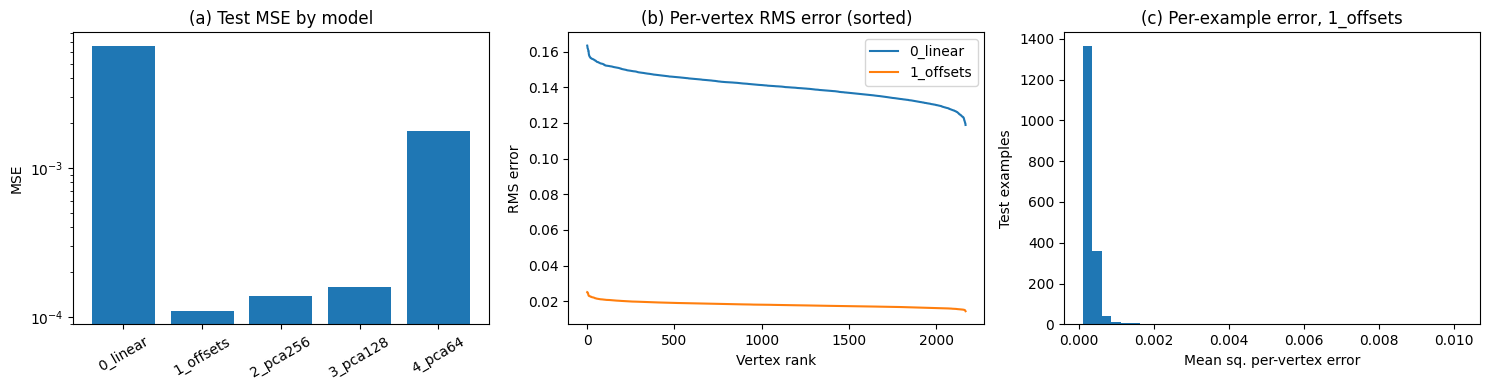

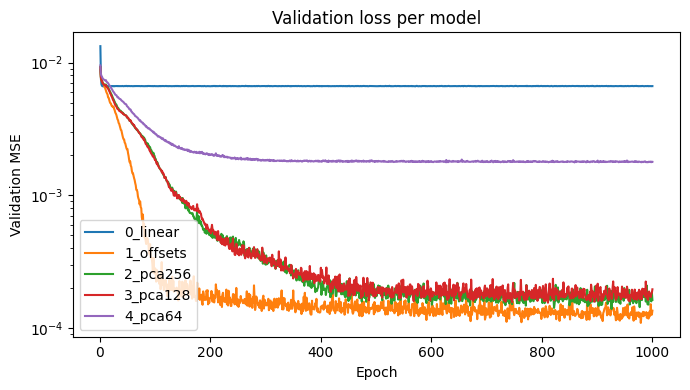

Easiest test example: idx 1335 (1.017e-04); hardest: idx 1244 (1.019e-02)


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
names = [r["model"] for r in results]
ax[0].bar(names, table["Test MSE"]); ax[0].set_yscale("log")
ax[0].set(title="(a) Test MSE by model", ylabel="MSE"); ax[0].tick_params(axis="x", rotation=30)
for n in ("0_linear", best):
    ax[1].plot(np.sort(np.sqrt(vert_err[n]))[::-1], label=n)
ax[1].set(title="(b) Per-vertex RMS error (sorted)", xlabel="Vertex rank", ylabel="RMS error"); ax[1].legend()
ax[2].hist(ex_err[best], bins=40)
ax[2].set(title=f"(c) Per-example error, {best}", xlabel="Mean sq. per-vertex error", ylabel="Test examples")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
for n, h in curves.items():
    plt.plot([e[0] for e in h], [e[2] for e in h], label=n)
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Validation MSE"); plt.title("Validation loss per model")
plt.legend(); plt.tight_layout(); plt.show()

order = np.argsort(ex_err[best])
print(f"Easiest test example: idx {order[0]} ({ex_err[best][order[0]]:.3e}); hardest: idx {order[-1]} ({ex_err[best][order[-1]]:.3e})")

## 6. Save results
Writes `results.json` and `results_table.csv` to the Colab session (download them from the file browser, or run the last lines to download directly).

In [ ]:
json.dump(dict(epochs=EPOCHS, lr=LR, best=best, results=results, k90=k90, k99=k99,
               curves={k: v for k, v in curves.items()}), open("results.json", "w"))
table.to_csv("results_table.csv", index=False)
print("saved results.json, results_table.csv")
try:
    from google.colab import files
    files.download("results.json"); files.download("results_table.csv")
except Exception as e:
    print("(not on Colab, skipping download)")

saved results.json, results_table.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Notes for the write-up
* Data is **synthetic** (same shapes as the paper); absolute numbers are not comparable with the paper.
* All models in Section 4 share lr, epochs, batch size and seed; the model is chosen on **validation** MSE and the test set is only used for reporting.
* Everything comes from a **single run with one seed**: treat small differences between models as ties.
* The paper's procedural-simulation runtime (~180 s) was measured with PhysBAM by the authors; we did not run it. Our timings are CPU/GPU inference time of the networks only.